calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


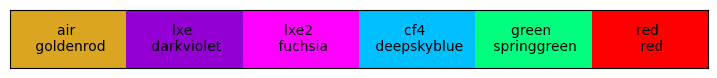

In [1]:
import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import pandas as pd
import matplotlib.pyplot as plt

from scipy import optimize as opt
from scipy.stats import norm
from scipy.stats import triang

import iminuit
from iminuit import Minuit
from scipy.ndimage import gaussian_filter1d

from PDEModel.OpticsDataLoader import *
import PDEModel.MathEquations as ME
import PDEModel.PhotonInfo as PI
# from PDEModel.PNJunction import *
import PDEModel.PNJunction as PNJ

import FittingTools.PDE_fittingTools as SS
from FittingTools import FittingFunctions as FF

import PDEModel.PDEStyle as MS
MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like

rad2deg = 180/np.pi

from IPython.display import display

# MS.ShowMyStyles() # for colors
# ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

In [2]:

# # plt.plot(mscaleValues, resultingScores)
# # print(mscaleValues[np.argmin(resultingScores)], min(resultingScores))


# ## fixed offset function testing
# def reduced_theta(theta, phi):
#     """
#     Calculate the reduced angle theta' where phi is zero.
    
#     Parameters:
#     theta (float): Incoming angle theta in radians.
#     phi (float): Incoming angle phi in radians.
    
#     Returns:
#     float: Reduced angle theta' in radians.
#     """
#     # Calculate the reduced angle theta'
#     theta_prime = np.arccos(np.cos(theta) * np.cos(phi))
    
#     return theta_prime

# # Example usage
# thetax_og = np.arange(0, np.pi, 0.01)
# # print("Reduced theta':", np.degrees(theta_prime))  # Convert radians to degrees for readability

# plt.figure(figsize=(6, 2))
# plt.plot(thetax_og * rad2deg, rad2deg * reduced_theta(theta = thetax_og, phi = 45/rad2deg), label="45 deg")
# plt.plot(thetax_og * rad2deg, rad2deg * reduced_theta(theta = thetax_og, phi = 5/rad2deg), label="5 deg")
# plt.plot(thetax_og * rad2deg, rad2deg * thetax_og, linestyle="--", label="y=x")

# plt.xlabel("Original theta (deg)")
# plt.ylabel("transformed theta' (deg)")
# plt.legend(title = "phi offset")

---
### Loading and showing raw data

In [3]:

class DataTaking:
    def __init__(self, vbr, asubtract, date, temp, mcWidth):
        self.vbr = vbr
        self.angleSubtract = asubtract
        self.date = date
        self.temp = temp
        self.mcWidth = mcWidth
        pass


class AngularObject:
    def __init__(self, v, wl, x, y, erry, RelativeError = False, darkCurrent = None, dcError = None):
        self.voltage = v
        self.wavelength = wl
        self.ewl = None
        
        self.xAngle = x
        self.yRaw = y
        self.yErr = erry
        
        self.yDark = darkCurrent
        self.yDarkErr = dcError
        
        if RelativeError:
            self.RelativeError = RelativeError
            self.errorFrac = np.round(np.average(self.yErr/self.yRaw), 4)
        else:
            self.RelativeError = False
            self.errorFrac = 0
        pass
    
        # self.yNormal = None
        # self.yNormError = None
        # self.yRelative = None
        # self.yRel_err = None

    # doesnt work well
    def GetSymmetric_xPoint(self, rangeToSearch, rangeToSymmetrize, Nsearch = 100):
        xMask = (self.xAngle > -rangeToSearch) & (self.xAngle < rangeToSearch)
        xDat = self.xAngle[xMask]
        yData = self.yRaw[xMask]
        
        fInterp = interp1d(xDat, yData, kind='cubic', fill_value='NaN', bounds_error=False)
        
        def symScore(xCenter):
            xM = np.linspace(-rangeToSymmetrize, xCenter, Nsearch)
            xP = np.linspace(xCenter, rangeToSymmetrize, Nsearch)
            yM = fInterp(xM)
            yP = fInterp(xP)
            score = np.sum( np.abs(yM - yP) )
            return score
        
        xAbout = np.linspace(-rangeToSymmetrize, rangeToSymmetrize, 100)
        scores = [symScore(x) for x in xAbout]
        minX = np.argmin(scores)
        return xAbout, scores
    
    def ShiftXdata(self, xShift):
        self.xAngle = self.xAngle+ xShift
        return
        
    
    def Normalize(self, xRange):
        xMask = (self.xAngle > -xRange) & (self.xAngle < xRange)
        
        self.yNormal = np.average(self.yRaw[xMask], weights=1/self.yErr[xMask]**2)
        self.yNormError = np.sqrt( np.sum( self.yErr[xMask]**2 ) ) / len(self.yRaw[xMask])
        
        # not doing SEM calculation, doing the weighted error of the data
        # if self.RelativeError:
        #     self.yNormError = self.yNormal * self.errorFrac / np.sqrt(len(self.yRaw[xMask]))
            # this is equal to error of the data (sigma) divided by sqrt(N)
        
        self.yRelative = self.yRaw / self.yNormal
        # calculate the error by the weighted error of the data
        self.yRel_err = self.yRelative * np.sqrt( (self.yErr/self.yRaw)**2 + (self.yNormError/self.yNormal)**2 )
        return

In [4]:
MCFWHM = 4.5 # nm/mm
mc1 = 2 # mm
mc2 = 0.5 # mm
mc3 = 2.5 # mm
# all with 2mm pinhole

globalCase = "C"

# just for separating the data
wlenBuf_data1 = 1.5

fPath_1 = os.path.join(VERA_DATA_PATH, "FBK_angular_current_oct2023.csv")
datTrack_data1 = DataTaking(vbr=26.625, asubtract=60, date="oct2023", temp=-110, mcWidth=mc1*MCFWHM)
d1_errorFrac = 0.01
dObjs_d1 = []

fPath_2 = os.path.join(VERA_DATA_PATH, "FBK_STD4_Angular_beammaps_0.5mmslit_T-110C.csv")
datTrack_data2 = DataTaking(vbr=27.95, asubtract=0, date="June2024", temp=-110, mcWidth=mc2 * MCFWHM)
dObjs_d2 = []

fPath_3 = os.path.join(VERA_DATA_PATH, "fbk_angular_sept2024/combined_400and600nm_-60and-100C.csv")
datTrack_data3 = DataTaking(vbr=None, asubtract=0, date="Sept2024", temp=-110, mcWidth=mc3 * MCFWHM)
dObjs_d3 = []

for fPath in [fPath_1, fPath_2, fPath_3]:
    if not os.path.exists(fPath):
        print(f"File not found: {fPath}")
        sys.exit()

---
### Assessing difference for Vuye n, k datasets

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-293K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


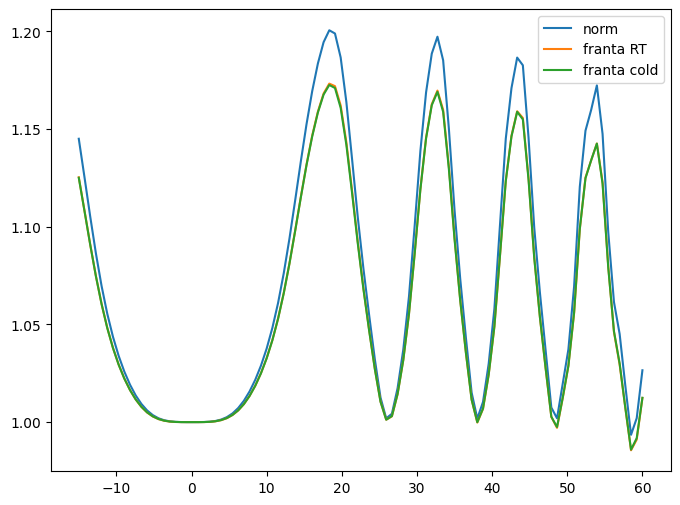

In [5]:
dh_franta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dh_frantaRT = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH,  "Franta_data", "Franta-293K.txt"))

xAngs = np.linspace(-15, 60, 100)
tRel_norm = FF.RelativeTrans_oxide(tOxide=1340, wlen = 160, theta1 = xAngs, smoothSigma=5, smoothStyle='triang', case=globalCase)

tRel_frantaRT = FF.RelativeTrans_oxide(tOxide=1340, wlen = 160, theta1 = xAngs, smoothSigma=5, smoothStyle='triang', dataHelper = dh_frantaRT, case=globalCase)
tRel_frantaCold = FF.RelativeTrans_oxide(tOxide=1340, wlen = 160, theta1 = xAngs, smoothSigma=5, smoothStyle='triang', dataHelper = dh_franta, case=globalCase)

plt.figure(figsize=(8, 6))
plt.plot(xAngs, tRel_norm, label="norm")
plt.plot(xAngs, tRel_frantaRT, label="franta RT")
plt.plot(xAngs, tRel_frantaCold, label="franta cold")

plt.legend()
plt.show()


---
### First dataset - October 2023

---- Oct 2023 Data ----
/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/veraData/FBK_angular_current_oct2023.csv
['Bias Voltage (V)' ' Photo-Current (A)' ' Angle (deg)' ' Wavelength (nm)']
reducing wlens check: True
all voltages: [2.005 4.005 6.005 8.005]
all wlens: [164.948 169.887 399.946 434.953 599.981 799.921]


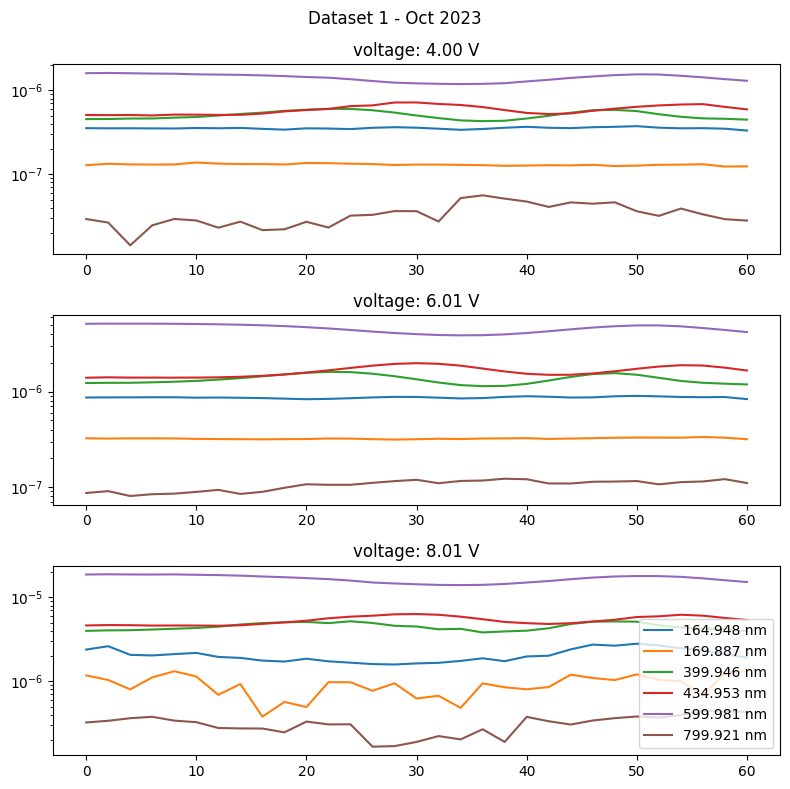

In [6]:

## oldest data
print("---- Oct 2023 Data ----")

print(fPath_1)
df = pd.read_csv(fPath_1, header=0)
# print(df.head())
# print(df.tail())

dfNames = df.columns
print(dfNames.values)
# data_anglesHR = df['Angle'].unique()
strV1 = dfNames[0]
strI1 = dfNames[1]
strA1 = dfNames[2]
strWlen1 = dfNames[3]

## fixing angles
df[strA1] = -1*(df[strA1] - datTrack_data1.angleSubtract)

#### grouping all the wavelengths that only differ by a small amount
d1_wlens_all = np.sort(df[strWlen1].unique())
# print(d1_wlens_all)
d1_wlens_reduced = []
for wlen in d1_wlens_all:
    if not d1_wlens_reduced or wlen - d1_wlens_reduced[-1] > wlenBuf_data1:
        d1_wlens_reduced.append(wlen)
d1_wlens_reduced = np.array(d1_wlens_reduced)
# print(d1_wlens_reduced)
for wlen in d1_wlens_reduced:
    dfWlen = df[(df[strWlen1] != wlen) & (np.abs(df[strWlen1] - wlen) < wlenBuf_data1)]
    extraWlens = dfWlen[strWlen1].unique()
    df[strWlen1].replace(extraWlens, wlen, inplace=True)
print("reducing wlens check:", np.all(df[strWlen1].unique() == d1_wlens_reduced))

## selecting breakdown voltage
df[strV1] = df[strV1] - datTrack_data1.vbr
d1_voltages = df[strV1].unique()
print("all voltages:", d1_voltages)
d1_vPick = max(d1_voltages)

print("all wlens:", d1_wlens_reduced)

##### plotting

d1v_use = d1_voltages[1:]
fig, axes = plt.subplots(len(d1v_use), 1, figsize=(8, 8))

for vPlot, ax in zip(d1v_use, axes):
    
    ax.set_title("voltage: %.2f V" % vPlot)
    # plotting all data
    for wl in d1_wlens_reduced:

        dfTemp = df[(df[strWlen1] == wl) & (df[strV1] == vPlot)]
        xDat = dfTemp[strA1]
        
        # yMinIndex = dfTemp[strI1].idxmin()
        # xOfMinY = df.loc[yMinIndex][strA1]
        # print(wl, xOfMinY)
        # yMin = df[df[strWlen1] == wl][strI1].min()
        
        yDat = dfTemp[strI1].values
        # yDat /= yDat[np.argmin(np.abs(xDat))]
        
        ax.semilogy(xDat, yDat, label=f"{wl} nm")

fig.suptitle("Dataset 1 - Oct 2023")
fig.tight_layout()
plt.legend()

---
### Second data - June 2024

---- June 2024 Data ----
lders/projects/vera/daaps/veraData/FBK_STD4_Angular_beammaps_0.5mmslit_T-110C.csv
['Angle (starting from -60deg)' 'Wavelength' 'Overvoltage' 'Current'
 'Error']
all wlens: [ 10.0116  159.952     9.98302 399.975   599.952   399.946  ]
voltages: [3 6]
physics wlens: [159.952 399.975 599.952]
3V dark currents: [7.82642e-11 4.11322e-11 3.61161e-11 3.42390e-11 2.77452e-11]
6V dark currents: [2.13911e-10 1.80330e-10 1.56422e-10 1.62673e-10 2.38388e-10]


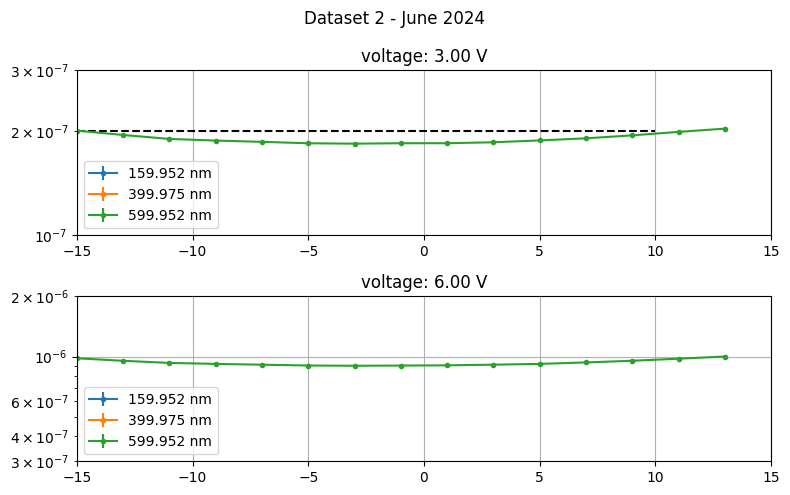

In [7]:

print("---- June 2024 Data ----")

print(fPath_2[40:])
df2 = pd.read_csv(fPath_2, header=0)
# print(df2.head())
# print(df2.tail())

df2Names = df2.columns
print(df2Names.values)
# data_anglesHR = df2['Angle'].unique()
strA2 = df2Names[0]
strWlen2 = df2Names[1]
strV2 = df2Names[2]
strI2 = df2Names[3]
strIerr2 = df2Names[4]

d2_voltages = df2[strV2].unique()
 
d2_wlens_all = df2[strWlen2].unique()
print("all wlens:", d2_wlens_all)
# getting rid of close excess wlen at 400
df2[strWlen2].replace(d2_wlens_all[-1], d2_wlens_all[3], inplace=True)

d2_wlens = df2[strWlen2].unique()

d2_wlens = d2_wlens[d2_wlens > 100]
print("voltages:", d2_voltages)
print("physics wlens:", d2_wlens)

## doing dark current subtraction
dfDark_3V = df2[(df2[strWlen2] < 50) & (df2[strV2] == d2_voltages[0])]
idark_3V = dfDark_3V[strI2].values
idark_3V_err = dfDark_3V[strIerr2].values
mask3v = idark_3V < np.mean(idark_3V)

idark_3V = idark_3V[mask3v] # the first dark current is too high so remove it via mask > mean
idark_3V_err = idark_3V_err[mask3v]
print("3V dark currents:", idark_3V)

dfDark_6V = df2[(df2[strWlen2] < 50) & (df2[strV2] == d2_voltages[1])]
idark_6V = dfDark_6V[strI2].values
idark_6V_err = dfDark_6V[strIerr2].values

mask6v = idark_6V < np.mean(idark_6V)
idark_6V = idark_6V[mask6v]
idark_6V_err = idark_6V_err[mask6v]
print("6V dark currents:", idark_6V)

fig, axes = plt.subplots(len(d2_voltages), 1, figsize=(8, 5))
for ax, v in zip(axes, d2_voltages):
    ax.set_title("voltage: %.2f V" % v)
    dfv = df2[df2[strV2] == v]
    dc = idark_3V if v == d2_voltages[0] else idark_6V
    for wl in d2_wlens:
        df2Wlen = dfv[(dfv[strWlen2] == wl)]
        # dfDark_i = df2Wlen.index
        # print(min(dfDark_i), max(dfDark_i))
        # print(df2.loc[[min(dfDark_i)-1, max(dfDark_i)+1]])
        
        xDat = df2Wlen[strA2].values
        yDat = df2Wlen[strI2].values - 1*np.mean(dc)
        yErr = df2Wlen[strIerr2].values
        
        ax.errorbar(xDat, yDat, yerr=yErr, marker = ".", label=f"{wl} nm")
        ax.set_yscale('log')
    
    ax.legend()
    
for ax in axes:
    ax.set_xlim(-15, 15)
    ax.grid()
axes[0].set_ylim(1e-7, 3e-7)
axes[0].hlines(2e-7, -15, 10, color='k', linestyle='--')

axes[1].set_ylim(0.3e-6, 2e-6)

fig.suptitle("Dataset 2 - June 2024")
fig.tight_layout()

---
### Third data - Sept 2024

---- Sept 2024 Data ----
lders/projects/vera/daaps/veraData/fbk_angular_sept2024/combined_400and600nm_-60and-100C.csv
['Angle (starting from -60deg)' 'Current' 'Error' 'wavelength (nm)'
 'temperature (K)' 'voltage (V)']
wavelengths: [400. 600.]
voltages: [6.]
temperatures: [213. 163.]
dark currents:
v1t1: [2.45334e-09 2.44886e-09 2.50328e-09 2.62781e-09]
v1t2: [8.81232e-11 1.19882e-10 1.64335e-10 2.11912e-10]


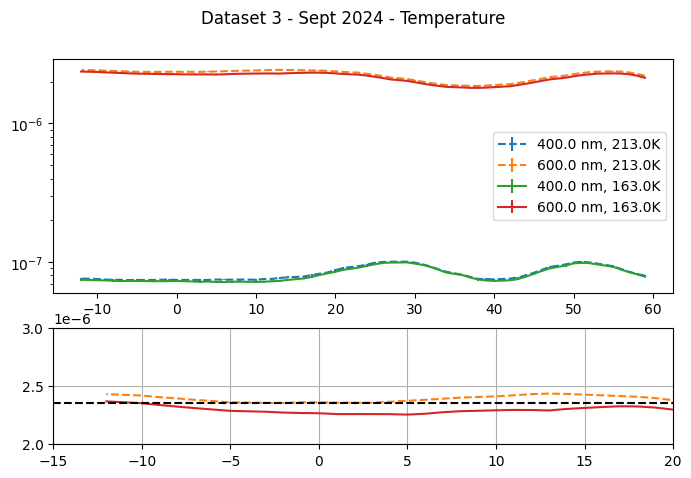

In [8]:

print("---- Sept 2024 Data ----")

print(fPath_3[40:])
df3 = pd.read_csv(fPath_3, header=0)
# print(df3.head())
# print(df3.tail())

df3Names = df3.columns
print(df3Names.values)
# data_anglesHR = df3['Angle'].unique()
strA3 = df3Names[0]
strI3 = df3Names[1]
strI3err = df3Names[2]
strWlen3 = df3Names[3]
strTemp3 = df3Names[4]
strV3 = df3Names[5]

d3_voltages = df3[strV3].unique()
d3_wlens = df3[strWlen3].unique()
d3_wlens = d3_wlens[d3_wlens > 100]
d3_temps = df3[strTemp3].unique()

print("wavelengths:", d3_wlens)
print("voltages:", d3_voltages)
print("temperatures:", d3_temps)

df_v1t1 = df3[(df3[strWlen3] < 50) & (df3[strTemp3] == d3_temps[0])]
df_v1t2 = df3[(df3[strWlen3] < 50) & (df3[strTemp3] == d3_temps[1])]

idark_v1t1 = df_v1t1[strI3].values
idark_v1t2 = df_v1t2[strI3].values

print("dark currents:")
print("v1t1:", idark_v1t1)
print("v1t2:", idark_v1t2)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), height_ratios=[2, 1])
for t in d3_temps:
    ls = '-'
    if t == d3_temps[0]:
        ls = '--'
    
    for wl in d3_wlens:
        df3Wlen = df3[(df3[strWlen3] == wl) & (df3[strV3] == d3_voltages[0]) & (df3[strTemp3] == t)]
        xDat = -df3Wlen[strA3].values[1:-2]
        yDat = df3Wlen[strI3].values[1:-2]
        yErr = df3Wlen[strI3err].values[1:-2]
        
        ax1.errorbar(xDat, yDat, yerr = yErr, label=f"{wl} nm, {t}K", ls=ls)
        ax1.set_yscale('log')
        
        ax2.plot(xDat, yDat, label=f"{wl} nm, {t}K", ls=ls)
        
plt.suptitle("Dataset 3 - Sept 2024 - Temperature")
ax1.legend()

ax2.set_xlim(-15, 20)
ax2.set_ylim(2e-6, 3e-6)
ax2.hlines(2.35e-6, -15, 20, color='k', linestyle='--')
ax2.grid()

---
### Building Normalized datasets

In [9]:
## is it possible xangle data is offset?
d2off = -2.5
d3off = -3.5

[164.948, 399.946, 434.953, 599.981]
Selected voltage: 6.01


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


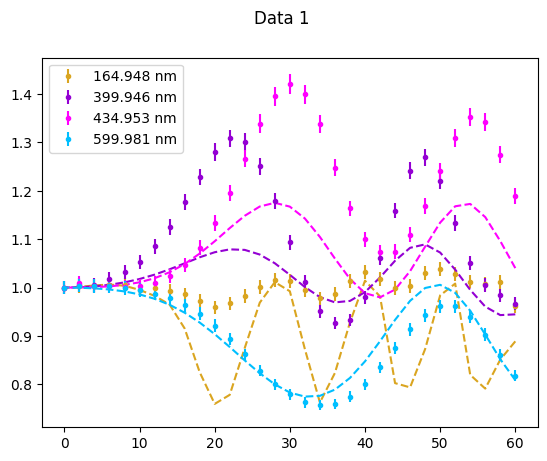

In [10]:

ms.ResetColorCycle()
## Building first dataset

## pick wlens
d1_wlenUse = [d1_wlens_reduced[0], d1_wlens_reduced[2], d1_wlens_reduced[3], d1_wlens_reduced[4]]
print(d1_wlenUse)

# d1_selectV = max(d1_voltages)
d1_selectV = d1_voltages[-2]
print("Selected voltage:", np.round(d1_selectV, 2))

dObjs_d1=[]
for wl in d1_wlenUse:
    dfWlen = df[(df[strWlen1] == wl) & (df[strV1] == d1_selectV)]
    xDat = dfWlen[strA1].values
    yDat = dfWlen[strI1].values
    yErr = yDat * d1_errorFrac
    
    ao = AngularObject(v=d1_selectV, wl=wl, x=xDat, y=yDat, erry=yErr, RelativeError=True)    
    ao.Normalize(xRange=2.0)
    dObjs_d1.append(ao)
    
    # plt.plot(ao.xAngle, ao.yRelative, label=f"{wl} nm")
    plt.errorbar(ao.xAngle, ao.yRelative, yerr = ao.yRel_err, color = ms.GetNextColor(), marker = ".", linestyle = "None", label=f"{wl} nm")
    
    if wl < 300:
        wl = 160
    yGuess = FF.RelativeTrans_oxide(tOxide=1330, wlen = wl, theta1 = ao.xAngle + 0, smoothSigma=datTrack_data1.mcWidth*3, smoothStyle='triang', case=globalCase)
    plt.plot(ao.xAngle, yGuess, ls='--', color = ms.GetNextColor(1))
    
plt.suptitle("Data 1")
plt.legend()

using voltage: 3
symmetric point: 2.8282828282828287
symmetric point: 6.545454545454547
symmetric point: 8.0


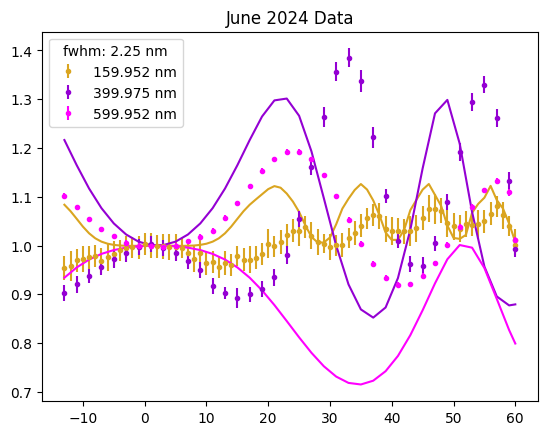

In [11]:

## building second datasets
ms.ResetColorCycle()

d2_wlenUse = d2_wlens
d2_selectV = d2_voltages[0]
print("using voltage:", d2_selectV)
# DC is negligible
dc2 = None
dcerr2 = None
# dc2 = idark_3V if d2_selectV == d2_voltages[0] else idark_6V 
# dcerr2 = idark_3V_err if d2_selectV == d2_voltages[0] else idark_6V_err

dObjs_d2 = []
for wl in d2_wlenUse:
    df2Wlen = df2[(df2[strWlen2] == wl) & (df2[strV2] == d2_selectV)]
    xDat = -df2Wlen[strA2].values
    yDat = df2Wlen[strI2].values #- 1*np.mean(dc2)
    yErr = df2Wlen[strIerr2].values #+ np.mean(idark_3V_err)**2)
    
    ao = AngularObject(v=d2_selectV, wl=wl, x=xDat, y=yDat, erry=yErr, RelativeError=False, darkCurrent=dc2, dcError=dcerr2)
    xScan, scores = ao.GetSymmetric_xPoint(rangeToSearch=15, rangeToSymmetrize=8)
    print("symmetric point:", xScan[np.argmin(scores)])
    # plt.plot(xScan, scores, label=f"{wl} nm")
    # ao.ShiftXdata(-2.5)
    ao.Normalize(xRange=2.0)
    dObjs_d2.append(ao)
    
    # plt.plot(ao.xAngle, ao.yRelative, label=f"{wl} nm")
    plt.errorbar(ao.xAngle, ao.yRelative, yerr = ao.yRel_err, color = ms.GetNextColor(), label=f"{wl} nm", marker = ".", linestyle = "None")
    
    if wl < 350:
        wl = wl-5
    yGuess = FF.RelativeTrans_oxide(tOxide=1330, wlen = wl, theta1 = ao.xAngle-2, smoothSigma=2*datTrack_data2.mcWidth, smoothStyle='triang', case=globalCase)
    plt.plot(ao.xAngle, yGuess, ls='-', color = ms.GetNextColor(1))
    
plt.title("June 2024 Data")

# yp = FF.RelativeTrans_oxide(tOxide=1390, wlen = 159, theta1 = ao.xAngle, smoothSigma=0.7, case=globalCase)
# yGuess = FF.RelativeTrans_oxide(tOxide=1400, wlen = 159, theta1 = ao.xAngle, smoothSigma=2.0, case=globalCase)

# plt.plot(ao.xAngle, yGuess, ls='-', color = 'k')
# plt.plot(ao.xAngle, yp, ls='--', color = 'k')
    
plt.legend(title=f"fwhm: {datTrack_data2.mcWidth} nm")

In [12]:
# # plot 15 deg  fixed over all wlens, see where we get a negative value value
# # then do for oxide thickness as well
# # oculd it be th
# wlRange = np.arange(160, 170, .2)

# # FF.RelativeTrans_oxide(tOxide=1390, wlen = wl, theta1 = ao.xAngle, smoothSigma=datTrack_data2.mcWidth, smoothStyle='box', case=globalCase)

# yAt20 = FF.RelativeTrans_oxide(tOxide=1340, wlen = wlRange, theta1 = 20., smoothSigma=datTrack_data1.mcWidth/2, smoothStyle='triang', case=globalCase)



# plt.vlines(165, 0.8, 1.6)
# plt.plot(wlRange, yAt20, ls='-', color = 'k')

selected temp: 163.0
symmetric point: -4.595959595959596
symmetric point: 0.3535353535353538
symmetric point: -1.9696969696969697
symmetric point: 3.282828282828282


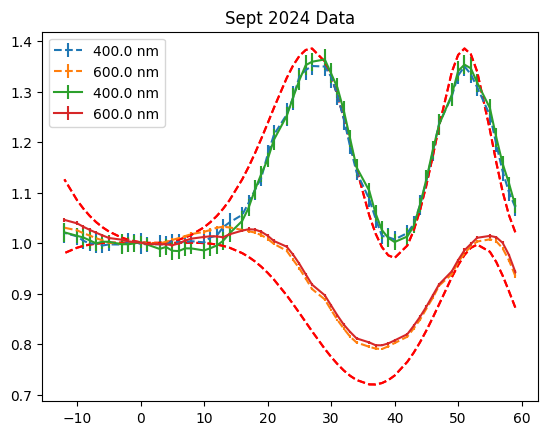

In [13]:

t3_pick = d3_temps[1]
print("selected temp:", t3_pick)

ms.ResetColorCycle()
dObjs_d3 = []

# dc3 = idark_v1t1 if t3_pick == d3_temps[0] else idark_v1t2
# dcerr3 = idark_v1t1 if t3_pick == d3_temps[0] else idark_v1t2

for t in d3_temps:
    ls = '-'
    if t == d3_temps[0]:
        ls = '--'
    for wl in d3_wlens:
        df3Wlen = df3[(df3[strWlen3] == wl) & (df3[strV3] == d3_voltages[0]) & (df3[strTemp3] == t)]
        xDat = -df3Wlen[strA3].values[1:-2]
        yDat = df3Wlen[strI3].values[1:-2]
        yErr = df3Wlen[strI3err].values[1:-2]
        
        ao = AngularObject(v=d3_voltages[0], wl=float(wl), x=xDat, y=yDat, erry=yErr, RelativeError=False)
        xScan, xScores = ao.GetSymmetric_xPoint(rangeToSearch=10, rangeToSymmetrize=5)
        print("symmetric point:", xScan[np.argmin(xScores)])
        ao.Normalize(xRange=2.0)
        plt.errorbar(ao.xAngle, ao.yRelative, yerr = ao.yRel_err, label=f"{wl} nm", linestyle = ls)
        
        if t == t3_pick:
            dObjs_d3.append(ao)
        
        wl = wl - 5
        yGuess = FF.RelativeTrans_oxide(tOxide=1330, wlen = wl, theta1 = ao.xAngle - 2, smoothSigma=datTrack_data3.mcWidth, smoothStyle='triang', case=globalCase)
        plt.plot(ao.xAngle, yGuess, ls='--', color = ms.GetNextColor(1))
            
plt.legend()      
plt.title("Sept 2024 Data")
plt.show()

---
### Testing different smoothing techniques

gaussian  

triangular  

box

experiment:  
many wavelengths --> raw signal --> divide by zero signal

In [14]:
from scipy.stats import norm
from scipy.stats import triang

[180. 181. 182. 183. 184. 185. 186. 187. 188. 189. 190. 191. 192. 193.
 194. 195. 196. 197. 198. 199. 200. 201. 202. 203. 204. 205. 206. 207.
 208. 209. 210. 211. 212. 213. 214. 215. 216. 217. 218. 219. 220.]


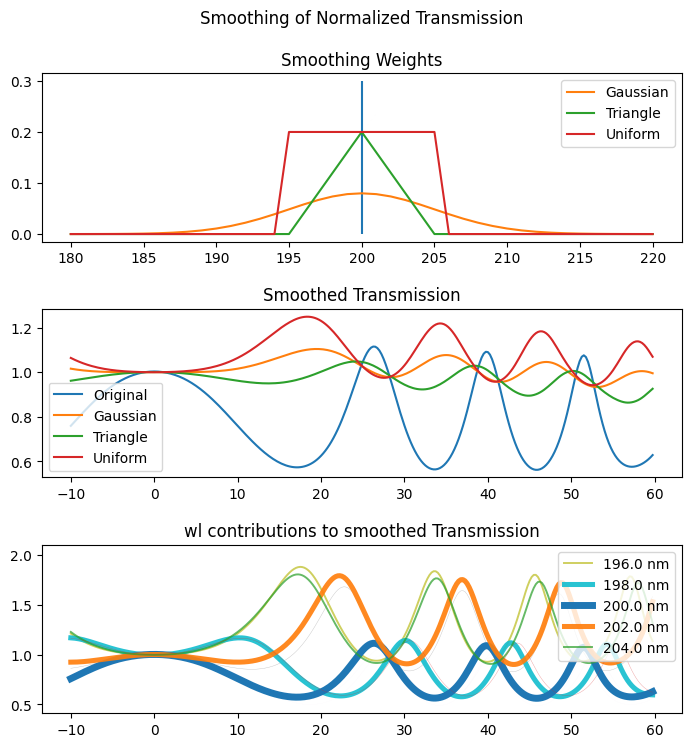

In [15]:
xAngles = np.arange(-10, 60, 0.25)
wlenCenter = 200
wlenSig = 10
tOx = 1360

## I think smoothing the normalized values may be different than
## smoothing the raw Transmission values, and then normalizing

# angular dependent values
def func_normalizedTrans(angles, wlenCenter, tox):
    photonAngle = PI.PhotonInfo(wlen=wlenCenter, theta_1=angles)
    tAngle = photonAngle.Wave_TotalTransmission(tox)
    tZero = np.mean(tAngle[np.abs(xAngles) < 2])
    tNorm = tAngle/tZero
    return tNorm

tNorm = func_normalizedTrans(xAngles, wlenCenter, tOx)

stepSize = wlenSig / 10
stepPast = 2
wlenSpan = np.arange(wlenCenter - stepPast*wlenSig, wlenCenter + stepPast*wlenSig+stepSize, stepSize)
print(wlenSpan)
loopedVals = np.array([func_normalizedTrans(xAngles, thisWlen, tOx) for thisWlen in wlenSpan])

weightGauss = norm.pdf(wlenSpan, wlenCenter, wlenSig/2)
tGauss = np.average(loopedVals, weights=weightGauss, axis=0)

weightTriangle = triang.pdf(wlenSpan, c=0.5, loc = wlenCenter-wlenSig/2, scale = wlenSig)
tTriangle = np.average(loopedVals, weights=weightTriangle, axis=0)

weightUniform = max(weightTriangle) * 1.0 * [(wlenSpan <= wlenCenter + wlenSig/2) & (wlenSpan > wlenCenter - wlenSig/2 - stepSize/2)][0]
tUniform = np.average(loopedVals, weights=weightUniform, axis=0)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 8))
fig.suptitle("Smoothing of Normalized Transmission")

ax1.set_title("Smoothing Weights")
ax1.vlines(wlenCenter, 0, 0.3)
ax1.plot(wlenSpan, weightGauss, linewidth = 0)
ax1.plot(wlenSpan, weightGauss, label="Gaussian")
ax1.plot(wlenSpan, weightTriangle, label="Triangle")

ax1.plot(wlenSpan, weightUniform, label="Uniform")

ax1.legend()
# print("integral check:", np.sum(weightGauss), np.sum(weightTriangle))

ax2.set_title("Smoothed Transmission")
ax2.plot(xAngles, tNorm, label="Original")
ax2.plot(xAngles, tGauss, label="Gaussian")
ax2.plot(xAngles, tTriangle, label="Triangle")
ax2.plot(xAngles, tUniform, label="Uniform")

ax2.legend()

ax3.set_title("wl contributions to smoothed Transmission")
for y, wl, wg in zip(loopedVals[::2], wlenSpan[::2], weightGauss[::2]):
    labSt = f"{wl} nm" if wg/max(weightGauss) > 0.5 else None
    ax3.plot(xAngles, y, alpha=wg/max(weightGauss), linewidth = 5*(wg/max(weightGauss))**4,label = labSt)
    
    # ax4.plot(xAngles, y, alpha=weight/max(weightGauss), label = f"{wl} nm")
ax3.legend()

fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1, wspace=0.4, hspace=0.4)

plt.show()

---
### Plotting all data together

[159.952 164.948 399.946 399.975 400.    434.953 599.952 599.981 600.   ]


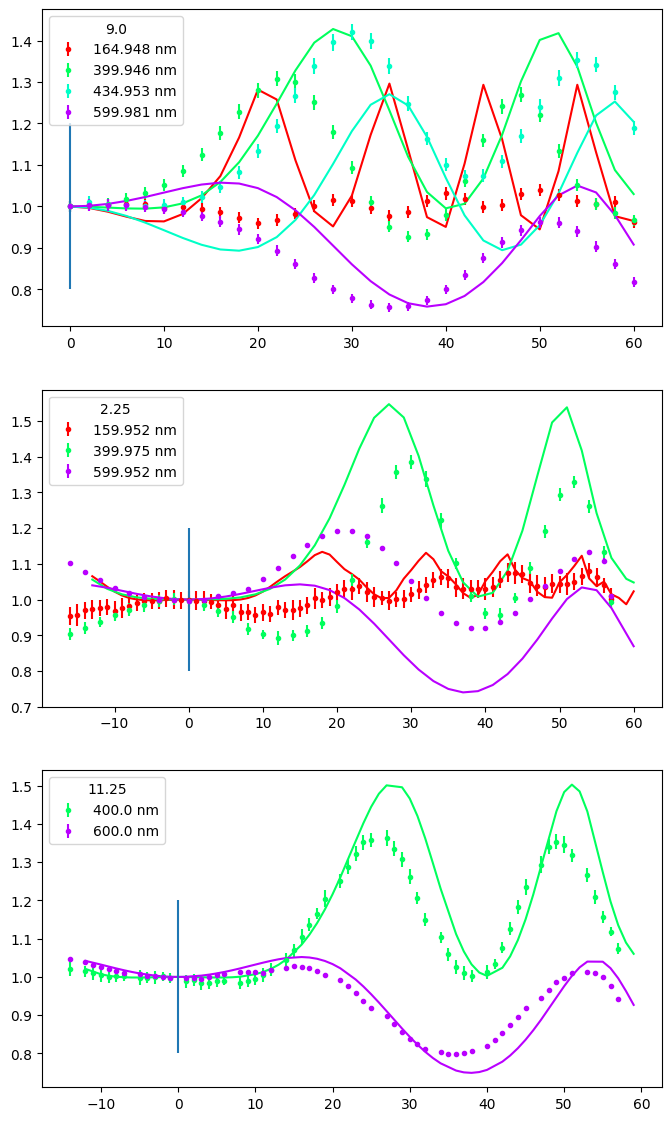

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(8, 14))
ax1, ax2, ax3 = axes

tOx = 1360
mcScale = 2
sStyle = 'box'

shift1wl = -1
shift2wl = 0
shift3wl = 0

d2xoff = -3
d3xoff = -2
skipWl = 20

for d1 in dObjs_d1:
    wl = d1.wavelength
    if wl < skipWl:
        continue
    
    col = MS.map_value_to_hsv(wl, 200, 700)
    ax1.errorbar(d1.xAngle, d1.yRelative, d1.yRel_err, color = col, label=f"{d1.wavelength} nm", marker = ".", linestyle = "None")

    yFunc = FF.RelativeTrans_oxide(tOxide=tOx, wlen = wl, theta1 = d1.xAngle, smoothSigma=mcScale*datTrack_data1.mcWidth, smoothStyle=sStyle, case=globalCase)
    ax1.plot(d1.xAngle, yFunc, color = col)
    
for d2 in dObjs_d2:
    wl = d2.wavelength
    if wl < skipWl:
        continue
    col = MS.map_value_to_hsv(wl, 200, 700)
    ax2.errorbar(d2.xAngle + d2xoff, d2.yRelative, d2.yRel_err, color = col, label=f"{d2.wavelength} nm", marker = ".", linestyle = "None")

    yFunc = FF.RelativeTrans_oxide(tOxide=tOx, wlen = wl, theta1 = d2.xAngle, smoothSigma=mcScale*datTrack_data2.mcWidth, smoothStyle=sStyle, case=globalCase)
    ax2.plot(d2.xAngle, yFunc, color = col)
    
for d3 in dObjs_d3:
    wl = d3.wavelength
    if wl < skipWl:
        continue
    col = MS.map_value_to_hsv(wl, 200, 700)
    ax3.errorbar(d3.xAngle + d3xoff, d3.yRelative, d3.yRel_err, color = col, label=f"{d3.wavelength} nm", marker = ".", linestyle = "None")

    yFunc = FF.RelativeTrans_oxide(tOxide=tOx, wlen = wl, theta1 = d3.xAngle, smoothSigma=0.5*mcScale*datTrack_data3.mcWidth, smoothStyle=sStyle, case=globalCase)
    ax3.plot(d3.xAngle, yFunc, color = col)

for ax, dinfo in zip(axes, [datTrack_data1, datTrack_data2, datTrack_data3]):
    ax.vlines(0, 0.8, 1.2)
    # ax.set_xlim(-15, 15)
    # ax.set_ylim(0.8, 1.2)
    # ax.grid()
    ax.legend(title=dinfo.mcWidth)

allWlens = np.concatenate(([d1.wavelength for d1 in dObjs_d1], [d2.wavelength for d2 in dObjs_d2], [d3.wavelength for d3 in dObjs_d3]))
print(np.unique(allWlens))


---
### Doing some fitting

__global__  
toxide  
mcWidthScaling  
wl1, wl2, wl3  
d1, d2, d3  


__nested__  


In [17]:
## not using my custom framework. doing it the 'manual' way
# allData = []

# for d1 in dObjs_d1:
#     d1_dataDict = {"wavelength": d1.wavelength, "theta1": d1.xAngle, "yVals": d1.yRelative, "yErrs": d1.yRel_err}
wlBuf = 2.
GLOBwlenMeasure = [160, 165, 400, 435, 600] # used globally
GLOBwlenSig = [5, 5, 4, 1, 4]

def selectClosestWlen_index(wl, wlList):
    return np.argmin(np.abs(wl - np.array(wlList)))

# selectClosestWlen_index(165, [160, 165, 400, 435, 600])

def selectWlenShift(wl, wlList, shiftList, buf = 2.):
    if len(wlList) != len(shiftList):
        print("length mismatch")
        return None
    index = selectClosestWlen_index(wl, wlList)
    closestWlen = wlList[index]
    if np.abs(wl - closestWlen) > buf:
        print(f"wlen difference greater than buffer. input: {wl}, closest {closestWlen}")
        return None
    return shiftList[index]

def fullScore_noPriorWeight(tOxide, mcScale,
                            dxo1, dxo2, dxo3,
                            wl160, wl165, wl400, wl435, wl600,
                            wlenToUse, wlbuf=2):
    score = 0
    ndata = 0
    shiftList = [wl160, wl165, wl400, wl435, wl600] # must match order of arguments and GLOB
    
    for d1 in dObjs_d1:
        wlShift = selectWlenShift(d1.wavelength, GLOBwlenMeasure, shiftList, wlBuf) # selecting the appropriate wlen shift
        
        if np.min(np.abs(d1.wavelength - wlenToUse)) > wlbuf: # only using the wlens we want to use
            # print("d1 skipping wlen:", d1.wavelength)
            continue
        
        yFunc = FF.RelativeTrans_oxide(tOxide=tOxide, wlen = d1.wavelength-wlShift, theta1 = d1.xAngle - dxo1, smoothSigma=mcScale*datTrack_data1.mcWidth, smoothStyle=sStyle, case=globalCase)
        score += np.sum((d1.yRelative - yFunc)**2 / d1.yRel_err**2)
        ndata += len(d1.yRelative)

    for d2 in dObjs_d2:
        if np.min(np.abs(d2.wavelength - wlenToUse)) > wlbuf:
            # print("d2 skipping wlen:", d2.wavelength)
            continue
        
        wlShift = selectWlenShift(d2.wavelength, GLOBwlenMeasure, shiftList, wlBuf)
        yFunc = FF.RelativeTrans_oxide(tOxide=tOxide, wlen = d2.wavelength-wlShift, theta1 = d2.xAngle - dxo2, smoothSigma=mcScale*datTrack_data2.mcWidth, smoothStyle=sStyle, case=globalCase)
        score += np.sum((d2.yRelative - yFunc)**2 / d2.yRel_err**2)
        ndata += len(d2.yRelative)
    
    for d3 in dObjs_d3:
        if np.min(np.abs(d3.wavelength - wlenToUse)) > wlbuf:
            # print("d3 skipping wlen:", d3.wavelength)
            continue
        wlShift = selectWlenShift(d3.wavelength, GLOBwlenMeasure, shiftList, wlBuf)
        yFunc = FF.RelativeTrans_oxide(tOxide=tOxide, wlen = d3.wavelength - wlShift, theta1 = d3.xAngle - dxo3, smoothSigma=mcScale*datTrack_data3.mcWidth, smoothStyle=sStyle, case=globalCase)
        score += np.sum((d3.yRelative - yFunc)**2 / d3.yRel_err**2)
        ndata += len(d3.yRelative)
    
    return score

In [18]:
allWlArgs = ["wl160", "wl165", "wl400", "wl435", "wl600"]
print(allWlens)

## values to include in fit
wlenUse = np.array([400, 435, 600])
# fullScore_noPriorWeight(1360, 1, *doxes, *wlshifts, wlenToUse=wlenUse)

def wrap_fullScore_np(tOxide, mcScale, dxo1, dxo2, dxo3, wl160, wl165, wl400, wl435, wl600):
    return fullScore_noPriorWeight(tOxide, mcScale, dxo1, dxo2, dxo3, wl160, wl165, wl400, wl435, wl600, wlenUse)

def wrap_fullScore_priorWl(tOxide, mcScale, dxo1, dxo2, dxo3, wl160, wl165, wl400, wl435, wl600):
    
    score = fullScore_noPriorWeight(tOxide, mcScale, dxo1, dxo2, dxo3, wl160, wl165, wl400, wl435, wl600, wlenUse)
    
    
    for wls, sigma in zip([wl160, wl165, wl400, wl435, wl600], GLOBwlenSig):
        
        penalty = (wls / sigma)**2 # mean is zero
        score += penalty
    return score

# initial values
doxes = [d2xoff, d2xoff, d3xoff]
wlshifts = [2, -1.5, 0, 0, 0]
print('test score:', wrap_fullScore_np(1330, 1.5, *doxes, *wlshifts))

# m_noprior = Minuit(wrap_fullScore_np, 1370, 1.5, *doxes, *wlshifts)
m_noprior = Minuit(wrap_fullScore_priorWl, 1370, 1.5, *doxes, *wlshifts)
m_noprior.tol = 100

# fixed parameters
wlFixs = ["wl160", "wl165"]
doxFix = ["dxo1", "dxo2", "dxo3"]
for fix in [*doxFix, *wlFixs]:
    m_noprior.fixed[fix] = True
    
m_noprior.limits["tOxide"] = (1300, 1400)
m_noprior.fixed["tOxide"] = True
# m_noprior.limits["mcScale"] = (0.1, 5)
m_noprior.fixed["mcScale"] = True


# wlShiftLimit = [-1, 1]
# toFloat_wlen = ["wl160", "wl165", "wl400"]
# for tf in toFloat_wlen:
#     m_noprior.limits[tf] = wlShiftLimit

m_noprior.limits["wl400"] = (-10, 10)
m_noprior.limits["wl435"] = (-10, 10)
m_noprior.limits["wl600"] = (-10, 10)

# m_noprior.limits["wl160"] = (-5, 5)
# m_noprior.limits["wl165"] = (-5, 5)

m_noprior.migrad()

[164.948 399.946 434.953 599.981 159.952 399.975 599.952 400.    600.   ]
test score: (177037.1165331435+0j)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minuit.py:791: ComplexWarning: Casting complex values to real discards the imaginary part
  fm = migrad(ncall, self._tolerance)


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 4.515e+04                  │              Nfcn = 69               │
│ EDM = 0.000439 (Goal: 0.2)       │            time = 1.9 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name    │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ tOxide  │  1.370e3  │  0.014e3  │            │            │  1300   │  1400   │  yes  │
│ 1 │ mcScale │   1.500   │   0.015   │            │            │         │         │  yes  │
│ 2 │ dxo1    │   -3.00   │   0.03    │            │            │         │         │  yes  │
│ 3 │ dxo2    │   -3.00   │   0.03    │            │            │         │         │  yes  │
│ 4 │ dxo3    │   -2.00   │   0.02    │            │            │         │         │  yes  │
│ 5 │ wl160   │   2.00    │   0.02    │            │            │         │         │  yes  │
│ 6 │ wl165   │  -1.500   │   0.015   │            │            │         │         │  yes  │
│ 7 │ wl400   │   2.37    │   0.06    │            │            │   -10   │   10    │       │
│ 8 │ wl435   │   -6.23   │   0.13    │            │            │   -10   │   10    │       │
│ 9 │ wl600   │  -0.687   │   0.031   │            │            │   -10   │   10    │       │
└───┴─────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌─────────┬───────────────────────────────────────────────────────────────────────────────────────────┐
│         │   tOxide  mcScale     dxo1     dxo2     dxo3    wl160    wl165    wl400    wl435    wl600 │
├─────────┼───────────────────────────────────────────────────────────────────────────────────────────┤
│  tOxide │        0        0        0        0        0        0        0   0.0000    0.000     0e-3 │
│ mcScale │        0        0        0        0        0        0        0   0.0000    0.000     0e-3 │
│    dxo1 │        0        0        0        0        0        0        0   0.0000    0.000     0e-3 │
│    dxo2 │        0        0        0        0        0        0        0   0.0000    0.000     0e-3 │
│    dxo3 │        0        0        0        0        0        0        0   0.0000    0.000     0e-3 │
│   wl160 │        0        0        0        0        0        0        0   0.0000    0.000     0e-3 │
│   wl165 │        0        0        0        0        0        0        0   0.0000    0.000     0e-3 │
│   wl400 │   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000  0.00326   0.0000        0 │
│   wl435 │    0.000    0.000    0.000    0.000    0.000    0.000    0.000   0.0000   0.0171        0 │
│   wl600 │     0e-3     0e-3     0e-3     0e-3     0e-3     0e-3     0e-3        0        0 0.000971 │
└─────────┴───────────────────────────────────────────────────────────────────────────────────────────┘

In [19]:
# from IPython.display import clear_output
# tox_values = np.arange(1360, 1400, 5.)
# scores = []
# shifts_wl = []
# for tox in tox_values:
#     m_noprior.fixto("tOxide", tox)
#     # m_noprior.values['wl400'] = wlshifts[2]
#     # m_noprior.values['wl435'] = wlshifts[3]
#     # m_noprior.values['wl600'] = wlshifts[4]
    
#     if tox % 2 == 0:
#         clear_output(wait=True)
#         print("at tOxide:", tox, end = "\r")
    
#     m_noprior.migrad()
#     score = m_noprior.fval
#     scores.append(score)
#     shifts_wl.append([m_noprior.values['wl400'], m_noprior.values['wl435'], m_noprior.values['wl600']])

In [20]:
# fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8))
# ax1.plot(tox_values, scores)
# shifts_wl = np.array(shifts_wl)

# ax2.plot(tox_values, shifts_wl[:, 0], label="400")
# ax2.plot(tox_values, shifts_wl[:, 1], label="435")
# ax2.plot(tox_values, shifts_wl[:, 2], label="600")
# ax2.hlines(0, 1360, 1400, color='k', linestyle='--')

# ax2.legend()
# plt.show()


1370.0
shifting: 164.948 by: -1.5
shifting: 399.946 by: 2.3664605219597483
shifting: 434.953 by: -6.229226701094301
shifting: 599.981 by: -0.6874036533062977
shifting: 159.952 by: 2.0
shifting: 399.975 by: 2.3664605219597483
shifting: 599.952 by: -0.6874036533062977


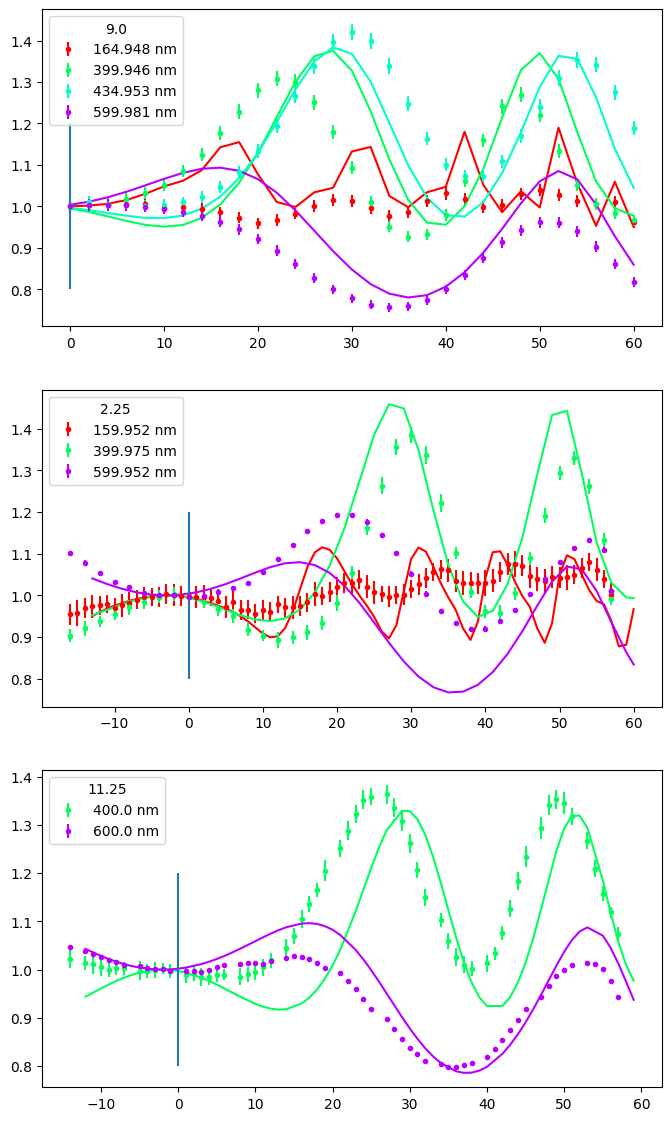

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(8, 14))
ax1, ax2, ax3 = axes

tox = m_noprior.values["tOxide"]
print(tox)
mcScale = m_noprior.values["mcScale"]
fitOffsets = [m_noprior.values[f] for f in allWlArgs]


for d1 in dObjs_d1:
    wl = d1.wavelength
    
    wlShift = selectWlenShift(wl, GLOBwlenMeasure, fitOffsets, wlBuf)
    print("shifting:", wl, "by:", wlShift)
    
    col = MS.map_value_to_hsv(wl, 200, 700)
    ax1.errorbar(d1.xAngle, d1.yRelative, d1.yRel_err, color = col, label=f"{d1.wavelength} nm", marker = ".", linestyle = "None")
    
    yFunc = FF.RelativeTrans_oxide(tOxide=tox, wlen = wl-wlShift, theta1 = d1.xAngle-m_noprior.values["dxo1"], smoothSigma=mcScale*datTrack_data1.mcWidth, smoothStyle=sStyle, case=globalCase)
    ax1.plot(d1.xAngle, yFunc, color = col)
    
for d2 in dObjs_d2:
    wl = d2.wavelength
    wlShift = selectWlenShift(wl, GLOBwlenMeasure, fitOffsets, wlBuf)
    print("shifting:", wl, "by:", wlShift)

    col = MS.map_value_to_hsv(wl, 200, 700)
    ax2.errorbar(d2.xAngle + d2xoff, d2.yRelative, d2.yRel_err, color = col, label=f"{d2.wavelength} nm", marker = ".", linestyle = "None")
    
    yFunc = FF.RelativeTrans_oxide(tOxide=tox, wlen = wl-wlShift, theta1 = d2.xAngle-m_noprior.values["dxo2"], smoothSigma=mcScale*datTrack_data2.mcWidth, smoothStyle=sStyle, case=globalCase)
    ax2.plot(d2.xAngle, yFunc, color = col)
    
for d3 in dObjs_d3:
    wl = d3.wavelength
    wlShift = selectWlenShift(wl, GLOBwlenMeasure, fitOffsets, wlBuf)

    col = MS.map_value_to_hsv(wl, 200, 700)
    ax3.errorbar(d3.xAngle + d3xoff, d3.yRelative, d3.yRel_err, color = col, label=f"{d3.wavelength} nm", marker = ".", linestyle = "None")

    yFunc = FF.RelativeTrans_oxide(tOxide=tox, wlen = wl-wlShift, theta1 = d3.xAngle-m_noprior.values["dxo3"], smoothSigma=mcScale*datTrack_data3.mcWidth, smoothStyle=sStyle, case=globalCase)
    ax3.plot(d3.xAngle, yFunc, color = col)

for ax, dinfo in zip(axes, [datTrack_data1, datTrack_data2, datTrack_data3]):
    ax.vlines(0, 0.8, 1.2)
    ax.legend(title=dinfo.mcWidth)

---
Trying floating each wavelength offset per dataset

In [22]:
def fullScore_byData_noprior(tOxide, mcScale,
                            dxo1, dxo2, dxo3,
                            wl1, wl2, wl3,
                            wlenToUse, dataToUse,
                            relError = False):
    score = 0
    ndata = 0

    wlbuf = 2.0 # for connecting wavelengths    
    if dataToUse[0] == 1:
        for d1 in dObjs_d1:
            wlShift = wl1
            err = d1.yRel_err if not relError else d1.yRelative * relError
            if np.min(np.abs(d1.wavelength - wlenToUse)) > wlbuf: # only using the wlens we want to use
                # print("d1 skipping wlen:", d1.wavelength)
                continue
            
            yFunc = FF.RelativeTrans_oxide(tOxide=tOxide, wlen = d1.wavelength-wlShift, theta1 = d1.xAngle - dxo1, smoothSigma=mcScale*datTrack_data1.mcWidth, smoothStyle=sStyle, case=globalCase)
            score += np.sum((d1.yRelative - yFunc)**2 / err**2)
            ndata += len(d1.yRelative)

    if dataToUse[1] == 1:
        for d2 in dObjs_d2:
            wlShift = wl2
            err = d2.yRel_err if not relError else d2.yRelative * relError
            if np.min(np.abs(d2.wavelength - wlenToUse)) > wlbuf:
                # print("d2 skipping wlen:", d2.wavelength)
                continue
            
            yFunc = FF.RelativeTrans_oxide(tOxide=tOxide, wlen = d2.wavelength-wlShift, theta1 = d2.xAngle - dxo2, smoothSigma=mcScale*datTrack_data2.mcWidth, smoothStyle=sStyle, case=globalCase)
            score += np.sum((d2.yRelative - yFunc)**2 / err**2)
            ndata += len(d2.yRelative)
            
    if dataToUse[2] == 1:
        for d3 in dObjs_d3:
            wlShift = wl3
            err = d3.yRel_err if not relError else d3.yRelative * relError
            if np.min(np.abs(d3.wavelength - wlenToUse)) > wlbuf:
                # print("d3 skipping wlen:", d3.wavelength)
                continue
            yFunc = FF.RelativeTrans_oxide(tOxide=tOxide, wlen = d3.wavelength - wlShift, theta1 = d3.xAngle - dxo3, smoothSigma=mcScale*datTrack_data3.mcWidth, smoothStyle=sStyle, case=globalCase)
            score += np.sum((d3.yRelative - yFunc)**2 / err**2)
            ndata += len(d3.yRelative)
    
    return score

In [23]:
# ## changing all errors to relative
# for dat in [dObjs_d1, dObjs_d2, dObjs_d3]:
#     for d in dat:
#         d.RelativeError = True
#         d.errorFraction = 0.01
#         d.yRel_err = d.errorFraction * d.yRelative

In [24]:
wlenUse_data = np.array([400, 435, 600])
dataUse = [1, 1, 1]
relError = False
fullScore_byData_noprior(1360, 1.5, 0, 0, 0, 0, 0, 0, wlenUse_data, dataUse)


def wrap_fullScore_byData_np(tOxide, mcScale, dxo1, dxo2, dxo3, wl1, wl2, wl3):
    
    return fullScore_byData_noprior(tOxide, mcScale, dxo1, dxo2, dxo3, wl1, wl2, wl3, wlenUse_data, dataUse, relError)
    

def wrap_fullScore_byData_prior(tOxide, mcScale, dxo1, dxo2, dxo3, wl1, wl2, wl3):
    
    fitScore = fullScore_byData_noprior(tOxide, mcScale, dxo1, dxo2, dxo3, wl1, wl2, wl3, wlenUse_data, dataUse, relError)
    
    # penalty for mc scaling
    dataRun_offsetSigma = 2.
    for wls in [wl1, wl2, wl3]:
        penalty = (wls / dataRun_offsetSigma)**2
        fitScore += penalty

    logVal = np.log10(mcScale)
    meanLog = np.log10(1.0)
    sigMClog = np.log10(2.0)
    penalty = (logVal - meanLog)**2 / sigMClog**2
    fitScore += penalty

    return fitScore

# initial values
doxes_data = [d2xoff, d2xoff, d3xoff]
wlshifts_data = [1, 10, 1.5]
print('test score:', wrap_fullScore_byData_np(1360, 1.5, *doxes_data, *wlshifts_data))

# m_noprior_data = Minuit(wrap_fullScore_np, 1370, 1.5, *doxes_data, *wlshifts_data)
m_noprior_data = Minuit(wrap_fullScore_byData_np, 1360, 1.5, *doxes_data, *wlshifts_data)
# m_noprior_data.tol = 10

# fixed parameters
allWlen_data_args = ["wl1", "wl2", "wl3"]
wlFixs = []
doxFix = ["dxo1", "dxo2", "dxo3"]
for fix in [*doxFix, *wlFixs]:
    m_noprior_data.fixed[fix] = True
    
m_noprior_data.limits["tOxide"] = (1300, 1400)
# m_noprior_data.fixed["tOxide"] = True
# m_noprior_data.limits["mcScale"] = (0.1, 5)
m_noprior_data.fixed["mcScale"] = True

m_noprior_data.limits["wl1"] = (-15, 10)
# m_noprior_data.fixto("wl1", 0)

m_noprior_data.limits["wl2"] = (-10, 15)
m_noprior_data.limits["wl3"] = (-10, 10)
# m_noprior_data.fixto("wl3", 0)


m_noprior_data.migrad()

test score: (22151.919946225084+0j)


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 1.714e+04                  │              Nfcn = 171              │
│ EDM = 1.52e-05 (Goal: 0.0002)    │            time = 3.8 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name    │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ tOxide  │ 1.3832e3  │ 0.0006e3  │            │            │  1300   │  1400   │       │
│ 1 │ mcScale │   1.500   │   0.015   │            │            │         │         │  yes  │
│ 2 │ dxo1    │   -3.00   │   0.03    │            │            │         │         │  yes  │
│ 3 │ dxo2    │   -3.00   │   0.03    │            │            │         │         │  yes  │
│ 4 │ dxo3    │   -2.00   │   0.02    │            │            │         │         │  yes  │
│ 5 │ wl1     │  -11.01   │   0.22    │            │            │   -15   │   10    │       │
│ 6 │ wl2     │   3.55    │   0.22    │            │            │   -10   │   15    │       │
│ 7 │ wl3     │   -7.93   │   0.26    │            │            │   -10   │   10    │       │
└───┴─────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌─────────┬─────────────────────────────────────────────────────────────────┐
│         │  tOxide mcScale    dxo1    dxo2    dxo3     wl1     wl2     wl3 │
├─────────┼─────────────────────────────────────────────────────────────────┤
│  tOxide │   0.372     0.0     0.0     0.0     0.0   -0.12   -0.13   -0.16 │
│ mcScale │     0.0       0       0       0       0    0.00    0.00    0.00 │
│    dxo1 │     0.0       0       0       0       0    0.00    0.00    0.00 │
│    dxo2 │     0.0       0       0       0       0    0.00    0.00    0.00 │
│    dxo3 │     0.0       0       0       0       0    0.00    0.00    0.00 │
│     wl1 │   -0.12    0.00    0.00    0.00    0.00  0.0493    0.04    0.05 │
│     wl2 │   -0.13    0.00    0.00    0.00    0.00    0.04  0.0492    0.06 │
│     wl3 │   -0.16    0.00    0.00    0.00    0.00    0.05    0.06  0.0696 │
└─────────┴─────────────────────────────────────────────────────────────────┘

1383.2229995303935
shifting d1 by: -11.00785460749295
shifting d2 by: 3.5546199220833614
shifting d3 by: -7.926250992924503
-------------------
using wlens: [400 435 600]
using data: [1, 1, 1]


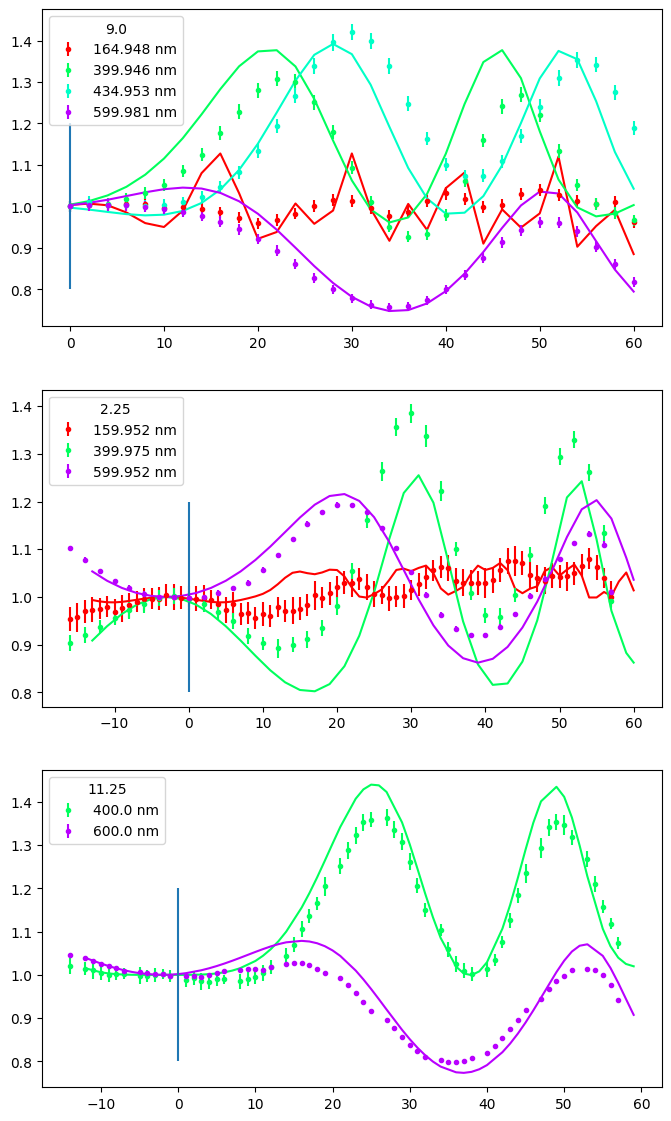

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(8, 14))
ax1, ax2, ax3 = axes

forceUVShift = 5

tox = m_noprior_data.values["tOxide"]
print(tox)
mcScale = m_noprior_data.values["mcScale"]
data_wl_Offsets = [m_noprior_data.values[f] for f in allWlen_data_args]
# print(data_wl_Offsets)

print("shifting d1 by:", data_wl_Offsets[0])
for d1 in dObjs_d1:
    wl = d1.wavelength
    
    wlShift = data_wl_Offsets[0]
    
    # if wl < 200:
    #     wl -= forceUVShift
    
    col = MS.map_value_to_hsv(wl, 200, 700)
    ax1.errorbar(d1.xAngle, d1.yRelative, d1.yRel_err, color = col, label=f"{d1.wavelength} nm", marker = ".", linestyle = "None")
    
    yFunc = FF.RelativeTrans_oxide(tOxide=tox, wlen = wl-wlShift, theta1 = d1.xAngle-m_noprior_data.values["dxo1"], smoothSigma=mcScale*datTrack_data1.mcWidth, smoothStyle=sStyle, case=globalCase)
    ax1.plot(d1.xAngle, yFunc, color = col)
    
print("shifting d2 by:", data_wl_Offsets[1])
for d2 in dObjs_d2:
    wl = d2.wavelength
    wlShift = data_wl_Offsets[1]
    
    if wl < 200:
        wl -= forceUVShift

    col = MS.map_value_to_hsv(wl, 200, 700)
    ax2.errorbar(d2.xAngle + d2xoff, d2.yRelative, d2.yRel_err, color = col, label=f"{d2.wavelength} nm", marker = ".", linestyle = "None")
    
    yFunc = FF.RelativeTrans_oxide(tOxide=tox, wlen = wl-wlShift, theta1 = d2.xAngle-m_noprior_data.values["dxo2"], smoothSigma=mcScale*datTrack_data2.mcWidth, smoothStyle=sStyle, case=globalCase)
    ax2.plot(d2.xAngle, yFunc, color = col)
    
print("shifting d3 by:", data_wl_Offsets[2])
for d3 in dObjs_d3:
    wl = d3.wavelength
    wlShift = data_wl_Offsets[2]

    col = MS.map_value_to_hsv(wl, 200, 700)
    ax3.errorbar(d3.xAngle + d3xoff, d3.yRelative, d3.yRel_err, color = col, label=f"{d3.wavelength} nm", marker = ".", linestyle = "None")

    yFunc = FF.RelativeTrans_oxide(tOxide=tox, wlen = wl-wlShift, theta1 = d3.xAngle-m_noprior_data.values["dxo3"], smoothSigma=mcScale*datTrack_data3.mcWidth, smoothStyle=sStyle, case=globalCase)
    ax3.plot(d3.xAngle, yFunc, color = col)

for ax, dinfo in zip(axes, [datTrack_data1, datTrack_data2, datTrack_data3]):
    ax.vlines(0, 0.8, 1.2)
    ax.legend(title=dinfo.mcWidth)
    
print("-------------------")
print("using wlens:", wlenUse_data)
print("using data:", dataUse)

## tracking fit results
what gives flat 160nm in data 2  
* normal errors
* include wlens [400, 435, 600]
* all 3 datasets

requires shifting by up to 10 nm

basically it is very hard to get the angular data to behave well.

---
# fitting each dataset separately

In [26]:
def fullScore_oneData(tOxide, mcScale, dxo, uvShift,
                      wlenToUse, dObjs, datTrack,
                      relError = False, dh = None):
    score = 0
    ndata = 0

    wlbuf = 2.0 # for connecting wavelengths
    func_sStyle ='triang'   
    
    for d1 in dObjs:
        err = d1.yRel_err if not relError else d1.yRelative * relError
        if np.min(np.abs(d1.wavelength - np.array(wlenToUse))) > wlbuf: # only using the wlens we want to use
            # print("d1 skipping wlen:", d1.wavelength)
            continue
        
        wl = d1.wavelength
        if wl < 200:
            wl += uvShift
        
        yFunc = FF.RelativeTrans_oxide(tOxide=tOxide, wlen = wl, theta1 = d1.xAngle + dxo, smoothSigma=mcScale*datTrack.mcWidth, smoothStyle=func_sStyle, dataHelper = dh, case=globalCase)
        score += np.sum((d1.yRelative - yFunc)**2 / err**2)
        ndata += len(d1.yRelative)
    
    return score

wlenUse_1 = [165, 400, 435, 600]
print("d1 wlens:", [d.wavelength for d in dObjs_d1])

relError = False
s1 = fullScore_oneData(1360, 1.5, 0, 0, wlenToUse=wlenUse_1, dObjs=dObjs_d1, datTrack=datTrack_data1)

glob_theDataInputs = {"wlenToUse": wlenUse_1, "dObjs": dObjs_d1, "datTrack": datTrack_data1, "relError": False, "dh": dh_franta}

def wrap_fullScore_oneData(tOxide, mcScale, dxo, uvShift):
    return fullScore_oneData(tOxide, mcScale, dxo, uvShift, **glob_theDataInputs)

d1 wlens: [164.948, 399.946, 434.953, 599.981]


In [27]:
mscaleValues = np.arange(1.0, 1.6, 0.01)
resultingScores = []

doDisplay = True
doUVfit = True

## doing the three fits
glob_theDataInputs["relError"] = 0.02

# all dh objects: None, dh_franta, dh_frantaRT
glob_theDataInputs["dh"] = dh_franta


# for ms in mscaleValues:

# mScale = 2.0
mScale = 1.32 # 1.3 from numerical minimization (roughly), see above forloop

scoreTotal = 0

## data 1
if doDisplay:
    print("--------------- data 1 ------------------")
glob_theDataInputs["wlenToUse"] = [400, 435, 600]
glob_theDataInputs["dObjs"] = dObjs_d1
glob_theDataInputs["datTrack"] = datTrack_data1

mData1 = Minuit(wrap_fullScore_oneData, 1320, mScale, 0, 0)
mData1.fixto("mcScale", mScale)
mData1.fixto("dxo", 0.0)
mData1.fixto("uvShift", 0)

if doDisplay:
    display(mData1.migrad())
else:
    mData1.migrad()

# print(mData1.errors)
# print(np.sqrt(np.diag(mData1.covariance)))
scoreTotal += mData1.fval

if doUVfit:
    ## data 1 only UV
    print("--------------- data 1 UV only ------------------")
    glob_theDataInputs["wlenToUse"] = [165]

    mData1_uv = Minuit(wrap_fullScore_oneData, 1340, mScale, 0, -8)
    mData1_uv.fixto("dxo", 0.0)
    mData1_uv.fixto("tOxide", mData1.values["tOxide"])

    mData1_uv.tol *= 15
    # mData1_uv.fixto("mcScale", 3)
    mData1_uv.limits["mcScale"] = (mScale, 3.5)

    # mData1_uv.fixto("uvShift", -12)
    mData1_uv.limits["uvShift"] = (-20, -5)
    
    display(mData1_uv.scan(ncall=1500))
    display(mData1_uv.hesse())
    # print(mData1_uv.covariance)
    
    

## data 2
if doDisplay:
    print("--------------- data 2 ------------------")
glob_theDataInputs["wlenToUse"] = [400, 600]
glob_theDataInputs["dObjs"] = dObjs_d2
glob_theDataInputs["datTrack"] = datTrack_data2

mData2 = Minuit(wrap_fullScore_oneData, 1340, mScale, 0, 0)
mData2.fixto("mcScale", mScale)
mData2.fixto("dxo", -2.5)
mData2.fixto("uvShift", 0)

if doDisplay:
    display(mData2.migrad())
else:
    mData2.migrad()

scoreTotal += mData2.fval

if doUVfit:
    ## only the 160nm data
    print("--------------- only 160nm from data2 ------------------")
    glob_theDataInputs["wlenToUse"] = [160]

    mData2_uv = Minuit(wrap_fullScore_oneData, 1350, mScale, 0, -3)
    mData2_uv.tol *= 15
    mData2_uv.fixto("tOxide", mData2.values["tOxide"])
    mData2_uv.fixto("dxo", -2.5)

    # mData2_uv.fixto("mcScale", mScale)
    mData2_uv.limits["mcScale"] = (0.4, 1.5)

    # mData2_uv.fixto("uvShift", -11)
    mData2_uv.limits["uvShift"] = (-20, -10)
    
    display(mData2_uv.scan(ncall=1500))
    display(mData2_uv.hesse())
    # print(mData2_uv.covariance)
    

## data 3
if doDisplay:
    print("---------------- data 3 -----------------")
glob_theDataInputs["wlenToUse"] = [400, 600]
glob_theDataInputs["dObjs"] = dObjs_d3
glob_theDataInputs["datTrack"] = datTrack_data3

mData3 = Minuit(wrap_fullScore_oneData, 1390, mScale, 0, 0)
mData3.fixto("mcScale", mScale)
mData3.fixto("dxo", -2.5)
mData3.fixto("uvShift", 0)

if doDisplay:
    display(mData3.migrad())
else:
    mData3.migrad()

scoreTotal += mData3.fval
resultingScores.append(scoreTotal)

--------------- data 1 ------------------


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 148.1                      │              Nfcn = 17               │
│ EDM = 2.5e-06 (Goal: 0.0002)     │            time = 0.2 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name    │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ tOxide  │ 1.3393e3  │ 0.0004e3  │            │            │         │         │       │
│ 1 │ mcScale │   1.320   │   0.013   │            │            │         │         │  yes  │
│ 2 │ dxo     │    0.0    │    0.1    │            │            │         │         │  yes  │
│ 3 │ uvShift │    0.0    │    0.1    │            │            │         │         │  yes  │
└───┴─────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌─────────┬─────────────────────────────────┐
│         │  tOxide mcScale     dxo uvShift │
├─────────┼─────────────────────────────────┤
│  tOxide │   0.189    0.00    0.00    0.00 │
│ mcScale │    0.00       0       0       0 │
│     dxo │    0.00       0       0       0 │
│ uvShift │    0.00       0       0       0 │
└─────────┴─────────────────────────────────┘

--------------- data 1 UV only ------------------


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minuit.py:945: ComplexWarning: Casting complex values to real discards the imaginary part
  r = self._fcn(x[: self.npar])
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minuit.py:964: ComplexWarning: Casting complex values to real discards the imaginary part
  fm = FunctionMinimum(self._fcn, self._last_state, self.strategy, edm_goal)


┌─────────────────────────────────────────────────────────────────────────┐
│                                 Scan                                    │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 40.08                      │             Nfcn = 1453              │
│ EDM = 0.489 (Goal: 1.5)          │            time = 4.4 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Hesse not run           │            NO covariance             │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name    │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ tOxide  │  1.339e3  │  0.013e3  │            │            │         │         │  yes  │
│ 1 │ mcScale │   2.322   │   0.004   │            │            │  1.32   │   3.5   │       │
│ 2 │ dxo     │    0.0    │    0.1    │            │            │         │         │  yes  │
│ 3 │ uvShift │  -14.32   │   0.05    │            │            │   -20   │   -5    │       │
└───┴─────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘

...

--------------- only 160nm from data2 ------------------


┌─────────────────────────────────────────────────────────────────────────┐
│                                 Scan                                    │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 89.33                      │             Nfcn = 1453              │
│ EDM = 4.71 (Goal: 1.5)           │            time = 5.4 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│         INVALID Minimum          │   ABOVE EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Hesse not run           │            NO covariance             │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name    │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ tOxide  │  1.384e3  │  0.014e3  │            │            │         │         │  yes  │
│ 1 │ mcScale │   0.727   │   0.008   │            │            │   0.4   │   1.5   │       │
│ 2 │ dxo     │   -2.5    │    0.1    │            │            │         │         │  yes  │
│ 3 │ uvShift │  -10.270  │   0.027   │            │            │   -20   │   -10   │       │
└───┴─────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘

┌─────────────────────────────────────────────────────────────────────────┐
│                                 Scan                                    │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 89.33                      │             Nfcn = 1467              │
│ EDM = 6.84 (Goal: 1.5)           │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name    │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ tOxide  │  1.384e3  │  0.014e3  │            │            │         │         │  yes  │
│ 1 │ mcScale │   0.727   │   0.010   │            │            │   0.4   │   1.5   │       │
│ 2 │ dxo     │   -2.5    │    0.1    │            │            │         │         │  yes  │
│ 3 │ uvShift │  -10.270  │   0.035   │            │            │   -20   │   -10   │       │
└───┴─────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌─────────┬─────────────────────────────────────┐
│         │   tOxide  mcScale      dxo  uvShift │
├─────────┼─────────────────────────────────────┤
│  tOxide │        0        0        0   0.0000 │
│ mcScale │        0 0.000106        0 -0.23e-3 │
│     dxo │        0        0        0   0.0000 │
│ uvShift │   0.0000 -0.23e-3   0.0000  0.00124 │
└─────────┴─────────────────────────────────────┘

---------------- data 3 -----------------


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 306                        │              Nfcn = 21               │
│ EDM = 1.53e-08 (Goal: 0.0002)    │            time = 0.1 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name    │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ tOxide  │ 1.3547e3  │ 0.0005e3  │            │            │         │         │       │
│ 1 │ mcScale │   1.320   │   0.013   │            │            │         │         │  yes  │
│ 2 │ dxo     │   -2.5    │    0.1    │            │            │         │         │  yes  │
│ 3 │ uvShift │    0.0    │    0.1    │            │            │         │         │  yes  │
└───┴─────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌─────────┬─────────────────────────────────┐
│         │  tOxide mcScale     dxo uvShift │
├─────────┼─────────────────────────────────┤
│  tOxide │   0.286    0.00    0.00    0.00 │
│ mcScale │    0.00       0       0       0 │
│     dxo │    0.00       0       0       0 │
│ uvShift │    0.00       0       0       0 │
└─────────┴─────────────────────────────────┘

In [28]:
# plt.plot(mscaleValues, resultingScores)
# print("min mcScale at:", mscaleValues[np.argmin(resultingScores)])

reduced score: 3.2885243208393615 NDOF = 288
-- all fit dicts --
data 1:		 {'tOxide': 1339.268703807873, 'mcScale': 1.32, 'dxo': 0.0, 'uvShift': 0.0}
data 1 UV:	 {'tOxide': 1339.268703807873, 'mcScale': 2.3216216216216217, 'dxo': 0.0, 'uvShift': -14.324324324324323}
data 2:		 {'tOxide': 1383.7319880863886, 'mcScale': 1.32, 'dxo': -2.5, 'uvShift': 0.0}
data 2 UV:	 {'tOxide': 1383.7319880863886, 'mcScale': 0.727027027027027, 'dxo': -2.5, 'uvShift': -10.27027027027027}
data 3:		 {'tOxide': 1354.7414029108493, 'mcScale': 1.32, 'dxo': -2.5, 'uvShift': 0.0}
total score: 947.0950044017361


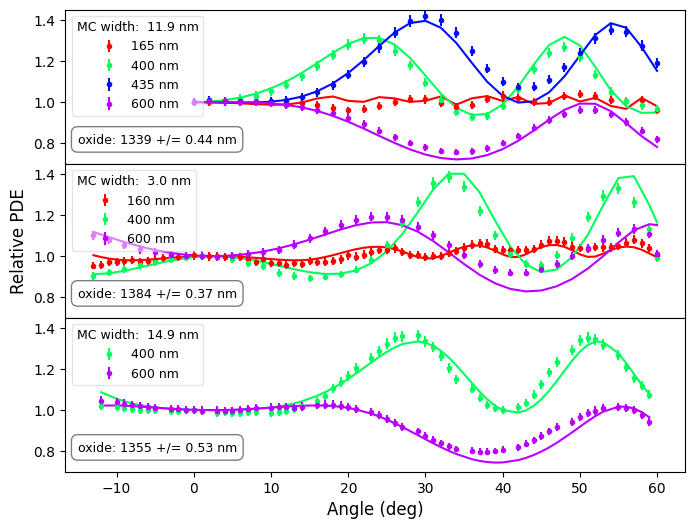

In [29]:
NDOF_total = np.sum([len(d.yRelative) if d.wavelength > 200 else 0 for d in dObjs_d1 + dObjs_d2 + dObjs_d3])
NDOF_total -= 3 # 3 fixed parameters

print("reduced score:", scoreTotal / NDOF_total, "NDOF =", NDOF_total)

fig, axes = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
ax1, ax2, ax3 = axes
relError = glob_theDataInputs["relError"]

this_sStyle = 'triang'

keyList = ["tOxide", "mcScale", "dxo", "uvShift"]

for d1 in dObjs_d1:
    fitDict = {k: mData1.values[k] for k in keyList}
    wl = d1.wavelength
    col = MS.map_value_to_hsv(wl, 200, 700)
    if wl > 415 and wl < 450:
        col = MS.map_value_to_hsv(wl + 100, 200, 700)
    
    if wl < 200:
        fitDict = {k: mData1_uv.values[k] for k in keyList}
    
    err = d1.yRel_err if not relError else d1.yRelative * relError
    ax1.errorbar(d1.xAngle, d1.yRelative, err, color = col, label=f"{d1.wavelength:.0f} nm", marker = ".", linestyle = "None")
    
    yFunc = FF.RelativeTrans_oxide(tOxide=fitDict["tOxide"], wlen = wl+fitDict["uvShift"], theta1 = d1.xAngle+fitDict["dxo"], smoothSigma= fitDict["mcScale"]*datTrack_data1.mcWidth, smoothStyle=this_sStyle, case=globalCase)
    ax1.plot(d1.xAngle, yFunc, color = col)

boxSpot = (0.02, 0.2)
boxStyle =dict(facecolor='white', alpha=0.5, edgecolor='k', boxstyle='round,pad=0.5')
ax1.text(boxSpot[0], boxSpot[1], f"oxide: {mData1.values['tOxide']:.0f} +/= {mData1.errors['tOxide']:0.2f} nm",
         transform=ax1.transAxes, fontsize=9, verticalalignment='top',
         bbox=boxStyle)

for d2 in dObjs_d2:
    fitDict = {k: mData2.values[k] for k in keyList}
    wl = d2.wavelength
    col = MS.map_value_to_hsv(wl, 200, 700)
    
    ## plotting data 2, 160nm fit
    if wl < 200:
        fitDict = {k: mData2_uv.values[k] for k in keyList}
    
    # print("wl:", wl, fitDict)
    err = d2.yRel_err if not relError else d2.yRelative * relError
    ax2.errorbar(d2.xAngle, d2.yRelative, err, color = col, label=f"{d2.wavelength:.0f} nm", marker = ".", linestyle = "None")
    yFunc = FF.RelativeTrans_oxide(tOxide=fitDict["tOxide"], wlen = wl + fitDict["uvShift"], theta1 = d2.xAngle+fitDict["dxo"], smoothSigma= fitDict["mcScale"]*datTrack_data2.mcWidth, smoothStyle=this_sStyle, case=globalCase)
    ax2.plot(d2.xAngle, yFunc, color = col)
    
    # yManual = 0.01 + FF.RelativeTrans_oxide(tOxide=1371.0, wlen = -11+dObjs_d2[0].wavelength, theta1 = -3+dObjs_d2[0].xAngle, smoothSigma= fitDict["mcScale"]*datTrack_data2.mcWidth, smoothStyle="triang", case=globalCase)
    # ax2.plot(dObjs_d2[0].xAngle, yManual, color = "k")
ax2.text(boxSpot[0], boxSpot[1], f"oxide: {mData2.values['tOxide']:.0f} +/= {mData2.errors['tOxide']:0.2f} nm",
         transform=ax2.transAxes, fontsize=9, verticalalignment='top',
         bbox=boxStyle)

for d3 in dObjs_d3:
    fitDict = {k: mData3.values[k] for k in keyList}
    wl = d3.wavelength
    col = MS.map_value_to_hsv(wl, 200, 700)
    
    err = d3.yRel_err if not relError else d3.yRelative * relError
    ax3.errorbar(d3.xAngle, d3.yRelative, err, color = col, label=f"{d3.wavelength:.0f} nm", marker = ".", linestyle = "None")
    yFunc = FF.RelativeTrans_oxide(tOxide=fitDict["tOxide"], wlen = wl + fitDict["uvShift"], theta1 = d3.xAngle+fitDict["dxo"], smoothSigma= fitDict["mcScale"]*datTrack_data3.mcWidth, smoothStyle=this_sStyle, case=globalCase)
    ax3.plot(d3.xAngle, yFunc, color = col)
    
ax3.text(boxSpot[0], boxSpot[1], f"oxide: {mData3.values['tOxide']:.0f} +/= {mData3.errors['tOxide']:0.2f} nm",
         transform=ax3.transAxes, fontsize=9, verticalalignment='top',
         bbox=boxStyle)
    
## copy y ticks from ax1 to ax2 and ax3
ax1.set_ylim(0.7, 1.45)
for ax in axes[1:]:
    ax.set_yticks(ax1.get_yticks())
    ax.set_yticklabels(ax1.get_yticklabels())
    ax.set_ylim(ax1.get_ylim())
    
for ax, dinfo in zip(axes, [datTrack_data1, datTrack_data2, datTrack_data3]):
    # ax.vlines(0, 0.8, 1.2)
    lTemp = ax.legend(title="MC width: " + f"{dinfo.mcWidth*fitDict['mcScale'] : 0.1f} nm", title_fontsize='9', fontsize='9')
    lTemp.get_frame().set_alpha(0.5)
    
ax3.set_xlabel("Angle (deg)", fontsize=12)
ax2.set_ylabel("Relative PDE", fontsize=12)

fig.subplots_adjust(hspace=0.)

print("-- all fit dicts --")
print("data 1:\t\t", {k: mData1.values[k] for k in keyList})
print("data 1 UV:\t", {k: mData1_uv.values[k] for k in keyList})
print("data 2:\t\t", {k: mData2.values[k] for k in keyList})
print("data 2 UV:\t", {k: mData2_uv.values[k] for k in keyList})
print("data 3:\t\t", {k: mData3.values[k] for k in keyList})

print("total score:", scoreTotal)

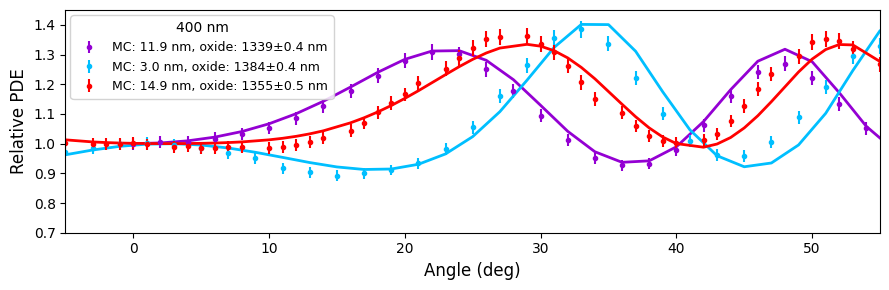

In [37]:
## Simplified plot: 400 nm only across all 3 datasets
fig_400, ax_400 = plt.subplots(figsize=(9, 3))

wl_target = 400
wl_tol = 5  # tolerance for matching wavelength

# distinct colors for each dataset
col_d1 = ms.lxe.col
col_d2 = ms.cf4.col
col_d3 = ms.red.col

this_sStyle = 'triang'

# Data 1 - 400 nm
for d1 in dObjs_d1:
    if np.abs(d1.wavelength - wl_target) < wl_tol:
        fitDict_d1 = {k: mData1.values[k] for k in keyList}
        err = d1.yRel_err if not relError else d1.yRelative * relError
        ax_400.errorbar(d1.xAngle, d1.yRelative, err, color=col_d1, 
                        marker=".", linestyle="None", 
                        label=f"MC: {datTrack_data1.mcWidth*fitDict_d1['mcScale']:.1f} nm, oxide: {mData1.values['tOxide']:.0f}±{mData1.errors['tOxide']:.1f} nm")
        yFunc = FF.RelativeTrans_oxide(tOxide=fitDict_d1["tOxide"], wlen=d1.wavelength + fitDict_d1["uvShift"], 
                                       theta1=d1.xAngle + fitDict_d1["dxo"], 
                                       smoothSigma=fitDict_d1["mcScale"]*datTrack_data1.mcWidth, 
                                       smoothStyle=this_sStyle, case=globalCase)
        ax_400.plot(d1.xAngle, yFunc, color=col_d1, linewidth=2)

# Data 2 - 400 nm
for d2 in dObjs_d2:
    if np.abs(d2.wavelength - wl_target) < wl_tol:
        fitDict_d2 = {k: mData2.values[k] for k in keyList}
        err = d2.yRel_err if not relError else d2.yRelative * relError
        ax_400.errorbar(d2.xAngle, d2.yRelative, err, color=col_d2, 
                        marker=".", linestyle="None",
                        label=f"MC: {datTrack_data2.mcWidth*fitDict_d2['mcScale']:.1f} nm, oxide: {mData2.values['tOxide']:.0f}±{mData2.errors['tOxide']:.1f} nm")
        yFunc = FF.RelativeTrans_oxide(tOxide=fitDict_d2["tOxide"], wlen=d2.wavelength + fitDict_d2["uvShift"], 
                                       theta1=d2.xAngle + fitDict_d2["dxo"], 
                                       smoothSigma=fitDict_d2["mcScale"]*datTrack_data2.mcWidth, 
                                       smoothStyle=this_sStyle, case=globalCase)
        ax_400.plot(d2.xAngle, yFunc, color=col_d2, linewidth=2)

# Data 3 - 400 nm
for d3 in dObjs_d3:
    if np.abs(d3.wavelength - wl_target) < wl_tol:
        fitDict_d3 = {k: mData3.values[k] for k in keyList}
        err = d3.yRel_err if not relError else d3.yRelative * relError
        ax_400.errorbar(d3.xAngle, d3.yRelative, err, color=col_d3, 
                        marker=".", linestyle="None",
                        label=f"MC: {datTrack_data3.mcWidth*fitDict_d3['mcScale']:.1f} nm, oxide: {mData3.values['tOxide']:.0f}±{mData3.errors['tOxide']:.1f} nm")
        yFunc = FF.RelativeTrans_oxide(tOxide=fitDict_d3["tOxide"], wlen=d3.wavelength + fitDict_d3["uvShift"], 
                                       theta1=d3.xAngle + fitDict_d3["dxo"], 
                                       smoothSigma=fitDict_d3["mcScale"]*datTrack_data3.mcWidth, 
                                       smoothStyle=this_sStyle, case=globalCase)
        ax_400.plot(d3.xAngle, yFunc, color=col_d3, linewidth=2)

ax_400.set_xlabel("Angle (deg)", fontsize=12)
ax_400.set_ylabel("Relative PDE", fontsize=12)
ax_400.set_ylim(0.7, 1.45)

leg_400 = ax_400.legend(title="400 nm", title_fontsize=10, fontsize=9, 
                        loc='upper left', fancybox=True, framealpha=0.85)
leg_400.get_frame().set_boxstyle('round', pad=0.1, rounding_size=0.3)

fig_400.tight_layout()

ax_400.set_xlim(-5, 55)
plt.show()